## Oresund

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate, lagged_fit, lagged_evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


FileNotFoundError: [Errno 2] No such file or directory: 'datasets/observations/stations.csv'

## Load Data and Measurement

In [3]:
# OPEN FOLDERS
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"
msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

ds = dfs.read(time = slice("2019-01-01", "2023-10-31"))

# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
#hf = ["Drogden", "Klagshamn", "Dragor", "Barseback"]
# availabilities 97-50-98-50
#alllist = [s for s in alllist if s.name in hf]

# Extract the values and convert to torch tensors

measurements = extract_water_level_measurements(alllist, ds_time=ds.time, obs_fldr=obs_fldr)
measurements = torch.as_tensor(measurements, dtype=torch.float32)
print("IN:\nMeasurements shape:", measurements.shape)

# Build a single mask for nodes that are valid in all output fields
surface = ds["Surface elevation"].values
u_velocity = ds["U velocity"].values
v_velocity = ds["V velocity"].values
valid_nodes = np.isfinite(surface).all(axis=0) & np.isfinite(u_velocity).all(axis=0) & np.isfinite(v_velocity).all(axis=0)

# outputs
H = torch.from_numpy(surface[:, valid_nodes].astype(np.float32, copy=False))
U = torch.from_numpy(u_velocity[:, valid_nodes].astype(np.float32, copy=False))
V = torch.from_numpy(v_velocity[:, valid_nodes].astype(np.float32, copy=False))

# print the shape of the arrays
print("OUT:\nH shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)

# free memory
del surface, u_velocity, v_velocity, valid_nodes, dfs

IN:
Measurements shape: torch.Size([84720, 13])
OUT:
H shape: torch.Size([84720, 3320])
U shape: torch.Size([84720, 3320])
V shape: torch.Size([84720, 3320])


In [ ]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.70        # percentage of data used for training 
VAL_SIZE = 0.15          # percentage of data used for validation
TEST_SIZE = 0.15         # percentage of data used for testing

COMPRESS_H = 20         # modes kept for H (surface elevation)
COMPRESS_U = 120         # modes kept for U (U velocity)
COMPRESS_V = 120         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Lagged-loss configuration
W_FACTOR = 0.7
W_KEEPED_TIMESTEPS = 16

# Architecture
ENCODER_DEPTH = 4               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64,128]     # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

# Persist every trained model checkpoint
MODEL_SAVE_DIR = Path("outputs") / "models_saved" / "Notebook2"
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

def save_model_checkpoint(model, model_name):
    model_path = MODEL_SAVE_DIR / f"{model_name}.pt"
    torch.save(model.state_dict(), model_path)
    print(f"Saved model checkpoint: {model_path}")

def load_model_checkpoint(model, model_name, map_location=device, eval_mode=True):
    model_path = MODEL_SAVE_DIR / f"{model_name}.pt"
    if not model_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {model_path}")

    state_dict = torch.load(model_path, map_location=map_location)
    model.load_state_dict(state_dict)
    model.to(map_location)
    if eval_mode:
        model.eval()
    print(f"Loaded model checkpoint: {model_path}")
    return model


## (T.3.F): Masking MHSA learned

In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 260])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 260])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 260])

Input shape for the model: 13
Output shape for the model: 260


Starting training...


Training:  56%|█████▌    | 112/200 [48:26<38:03, 25.95s/it, Train Loss=0.00313, Val Loss=0.00370, Patience=39, Best Val Loss=0.00364, LR=3.99e-04] 

Early stopping at epoch 113
Training completed with best validation loss: 0.0036
Saved model checkpoint: outputs/RUNL/models/T.3.F_masking_MHSA_learned.pt


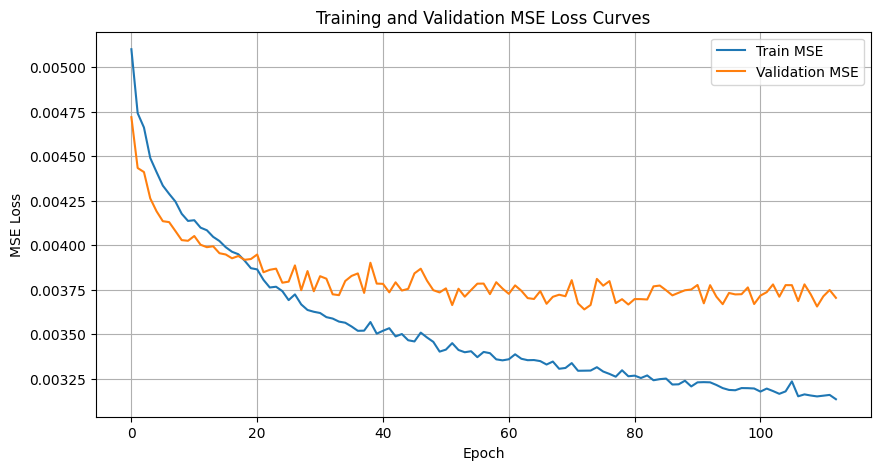

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003294,0.003639,0.003972,0.126998,0.133714,0.136153


In [6]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshredA = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshredA, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )
save_model_checkpoint(mshredA, "T.3.F_masking_MHSA_learned")

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshredA, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [7]:
del train_dataset, val_dataset, test_dataset

## (T.3.F.LAGGED): Masking MHSA learned

In [8]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, pad_output=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1] 
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 24, 260])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 24, 260])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 24, 260])

Input shape for the model: 13
Output shape for the model: 260


Lagged loss weights (W): 
[0.         0.         0.         0.         0.         0.
 0.         0.         0.00142902 0.00204145 0.00291636 0.00416623
 0.00595176 0.00850251 0.01214645 0.01735207 0.02478867 0.03541239
 0.05058913 0.07227018 0.10324311 0.14749016 0.21070021 0.30100033]
Starting training...


Training:  46%|████▌     | 92/200 [1:15:18<1:28:24, 49.11s/it, Train Loss=0.00317, Val Loss=0.00371, Patience=39, Best Val Loss=0.00361, LR=5.55e-04]

Early stopping at epoch 93
Training completed with best validation loss: 0.0036
Saved model checkpoint: outputs/RUNL/models/T.3.F.LAGGED_masking_MHSA_learned.pt


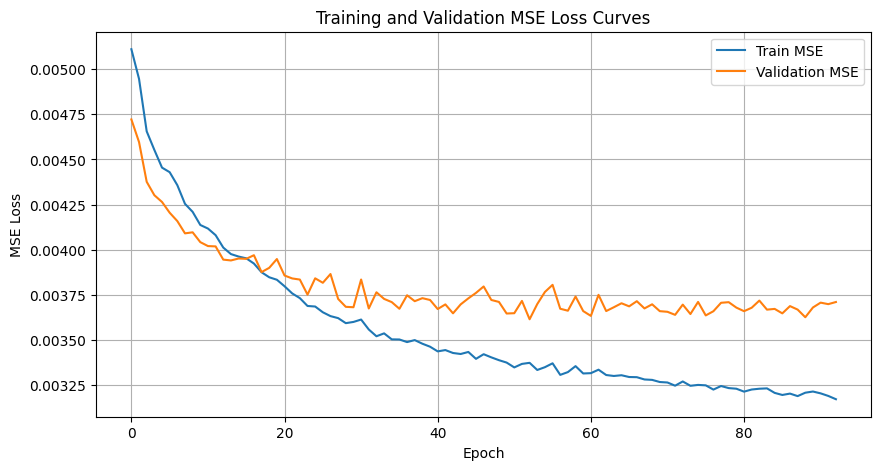

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003294,0.003639,0.003972,0.126998,0.133714,0.136153
1,(mSHRED): TR+cnn,"(T.3.F.LAGGED): masking MHSA learned (w=0.7, k...",0.003372,0.003614,0.003922,0.128589,0.133400,0.135156


In [9]:
# Lagged training configuration for 3D decoder
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
    decoder_3D=True,
)
mshredB = mSHRED(args=model_args).to(device)

train_errors, valid_errors = lagged_fit(
    mshredB, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE, w_factor=W_FACTOR, w_keeped_steps=W_KEEPED_TIMESTEPS,
)
save_model_checkpoint(mshredB, "T.3.F.LAGGED_masking_MHSA_learned")

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    lagged_evaluate, mshredB, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type=f"(T.3.F.LAGGED): masking MHSA learned (w={W_FACTOR}, k={W_KEEPED_TIMESTEPS})",
    masking_type=MASKING_TYPE,
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


In [10]:
del train_dataset, val_dataset, test_dataset

## (T.3.G): Masking x2 channels + MHSA learned

In [11]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 260])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 260])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 260])

Input shape for the model: 13
Output shape for the model: 260


Starting training...


Training:  48%|████▊     | 95/200 [38:46<42:51, 24.49s/it, Train Loss=0.00321, Val Loss=0.00373, Patience=39, Best Val Loss=0.00364, LR=5.31e-04]  

Early stopping at epoch 96
Training completed with best validation loss: 0.0036
Saved model checkpoint: outputs/RUNL/models/T.3.G_masking_x2_channels_MHSA_learned.pt


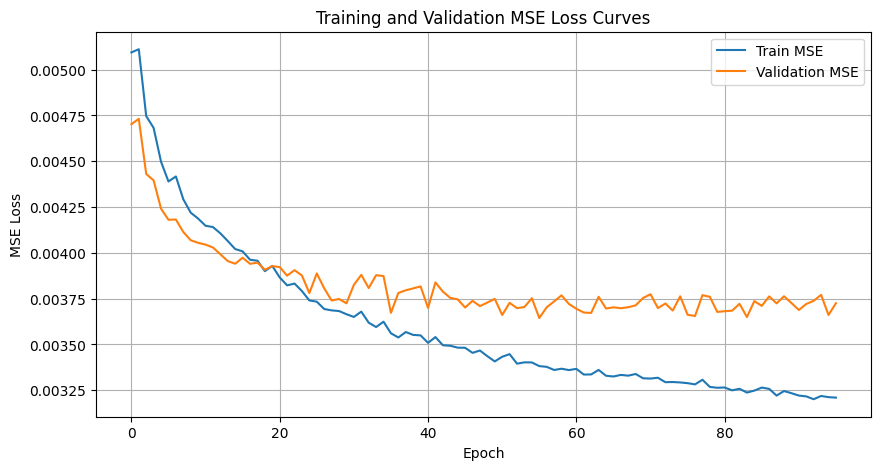

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003294,0.003639,0.003972,0.126998,0.133714,0.136153
1,(mSHRED): TR+cnn,"(T.3.F.LAGGED): masking MHSA learned (w=0.7, k...",0.003372,0.003614,0.003922,0.128589,0.133400,0.135156
2,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.003381,0.003644,0.003930,0.128813,0.133966,0.135843


In [12]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshredC = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshredC, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )
save_model_checkpoint(mshredC, "T.3.G_masking_x2_channels_MHSA_learned")

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshredC, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [13]:
del train_dataset, val_dataset, test_dataset

## (T.3.G.LAGGED): Masking x2 channels + MHSA learned


In [14]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, pad_output=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1] 
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 24, 260])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 24, 260])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 24, 260])

Input shape for the model: 13
Output shape for the model: 260


Lagged loss weights (W): 
[0.         0.         0.         0.         0.         0.
 0.         0.         0.00142902 0.00204145 0.00291636 0.00416623
 0.00595176 0.00850251 0.01214645 0.01735207 0.02478867 0.03541239
 0.05058913 0.07227018 0.10324311 0.14749016 0.21070021 0.30100033]
Starting training...


Training:  40%|████      | 80/200 [1:03:56<1:35:54, 47.95s/it, Train Loss=0.00323, Val Loss=0.00375, Patience=39, Best Val Loss=0.00368, LR=6.47e-04]

Early stopping at epoch 81
Training completed with best validation loss: 0.0037
Saved model checkpoint: outputs/RUNL/models/T.3.G.LAGGED_masking_x2_channels_MHSA_learned.pt


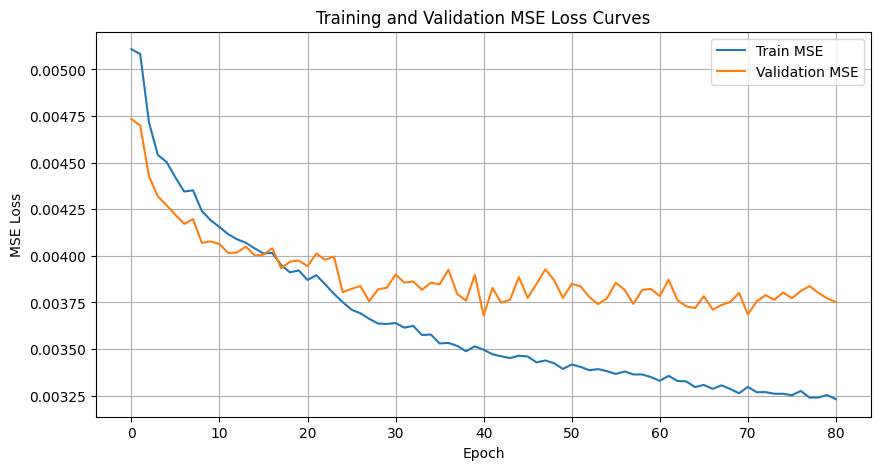

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003294,0.003639,0.003972,0.126998,0.133714,0.136153
1,(mSHRED): TR+cnn,"(T.3.F.LAGGED): masking MHSA learned (w=0.7, k...",0.003372,0.003614,0.003922,0.128589,0.133400,0.135156
2,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.003381,0.003644,0.003930,0.128813,0.133966,0.135843
3,(mSHRED): TR+cnn,(T.3.G.LAGGED): masking x2 channels + MHSA lea...,0.003496,0.003679,0.003981,0.131022,0.134593,0.136140


In [15]:
# Lagged training configuration for 3D decoder with x2 channels
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
    decoder_3D=True,
)
mshredD = mSHRED(args=model_args).to(device)

train_errors, valid_errors = lagged_fit(
    mshredD, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE, w_factor=W_FACTOR, w_keeped_steps=W_KEEPED_TIMESTEPS,
)
save_model_checkpoint(mshredD, "T.3.G.LAGGED_masking_x2_channels_MHSA_learned")

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    lagged_evaluate, mshredD, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type=f"(T.3.G.LAGGED): masking x2 channels + MHSA learned (w={W_FACTOR}, k={W_KEEPED_TIMESTEPS})",
    masking_type=MASKING_TYPE,
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


In [16]:
del train_dataset, val_dataset, test_dataset

## Results

In [ ]:
dataframe_errors = pd.read_csv("results_df/Notebook2/dataframe_errors.csv")
display(dataframe_errors)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.3.F): masking MHSA learned,0.003294,0.003639,0.003972,0.126998,0.133714,0.136153
1,(mSHRED): TR+cnn,"(T.3.F.LAGGED): masking MHSA learned (w=0.7, k...",0.003372,0.003614,0.003922,0.128589,0.133400,0.135156
2,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.003481,0.003744,0.004000,0.129813,0.134966,0.136843
3,(mSHRED): TR+cnn,(T.3.G.LAGGED): masking x2 channels + MHSA lea...,0.003496,0.003679,0.003981,0.131022,0.134593,0.136140


Saved PDF and PNG.


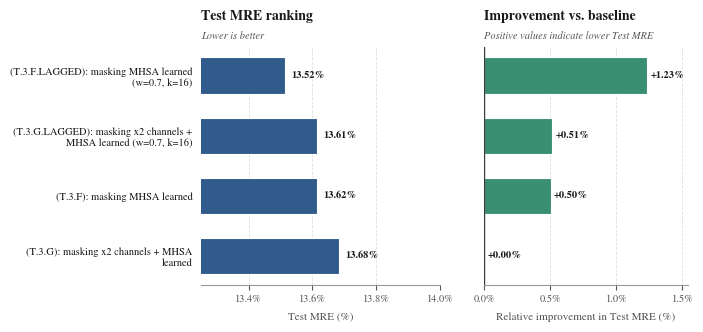

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap
from matplotlib.ticker import FuncFormatter

# ============================================================
# PAPER-READY SETTINGS
# ============================================================
# - Vector-safe fonts (Type 42) so PDF/EPS embed correctly in LaTeX
# - Serif font to match most journal body text (swap to sans if your
#   venue uses a sans-serif font, e.g. "DejaVu Sans" / "Arial")
# - White background (no off-white/slide-deck backdrop)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "axes.unicode_minus": False,
})

# Set BASELINE_PATTERN to the substring identifying your baseline row
# (e.g. "T.0"). If no row matches, the code falls back to using the
# worst-performing (highest test-mre) row as the reference point.
BASELINE_PATTERN = "T.0"

# ============================================================
# LOAD DATA
# ============================================================

dataframe_errors = pd.read_csv("dataframe_errors.csv")

df_plot = (
    dataframe_errors
    .sort_values("test-mre")
    .reset_index(drop=True)
    .copy()
)

baseline_mask = df_plot["type"].str.contains(BASELINE_PATTERN, regex=False)

if baseline_mask.any():
    baseline_idx = df_plot.index[baseline_mask][0]
    baseline_test_mre = df_plot.loc[baseline_idx, "test-mre"]
else:
    baseline_idx = None
    baseline_test_mre = df_plot["test-mre"].max()

# Convert to percentage
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_baseline_%"] = (
    100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre
)

# Wrap labels
df_plot["type_wrapped"] = [
    "\n".join(textwrap.wrap(str(s), width=38))
    for s in df_plot["type"]
]

n_models = len(df_plot)
y = np.arange(n_models)

# ============================================================
# STYLE — print-safe palette (also fine in grayscale)
# ============================================================

BLUE = "#315B8A"
GREEN = "#3A8F72"
RED = "#C65A54"
GOLD = "#D39B32"

TEXT = "#1A1A1A"
SECONDARY = "#555555"
GRID = "#DADADA"

# ============================================================
# FIGURE — sized for a double-column journal figure
# (7.16 in is the standard IEEE/Elsevier two-column text width;
#  use 3.5 in single-column if you stack panels vertically instead)
# ============================================================

FIG_WIDTH_IN = 7.16
fig_height = max(2.6, 0.45 * n_models + 1.6)

fig, axes = plt.subplots(
    1, 2,
    figsize=(FIG_WIDTH_IN, fig_height),
    gridspec_kw={"width_ratios": [1.08, 0.92], "wspace": 0.20},
)
fig.patch.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("white")


def add_panel_title(ax, title, subtitle):
    ax.text(0.0, 1.10, title, transform=ax.transAxes, fontsize=10,
             fontweight="bold", color=TEXT, ha="left", va="bottom")
    ax.text(0.0, 1.025, subtitle, transform=ax.transAxes, fontsize=7.5,
             color=SECONDARY, ha="left", va="bottom", style="italic")


# ============================================================
# LEFT PANEL — TEST MRE RANKING
# ============================================================

ax = axes[0]
bars = ax.barh(y, df_plot["test-mre_%"], height=0.6, color=BLUE,
                edgecolor="white", linewidth=0.8)

if baseline_idx is not None:
    bars[baseline_idx].set_color(GOLD)

ax.set_yticks(y)
ax.set_yticklabels(df_plot["type_wrapped"], fontsize=7.5, color=TEXT)
ax.invert_yaxis()

add_panel_title(ax, "Test MRE ranking", "Lower is better")
ax.set_xlabel("Test MRE (%)", fontsize=8, color=SECONDARY, labelpad=6)

# Auto-range with a small margin instead of a hardcoded 12-15 window,
# so the script generalizes to other data
lo = np.floor(df_plot["test-mre_%"].min() * 4) / 4 - 0.25
hi = np.ceil(df_plot["test-mre_%"].max() * 4) / 4 + 0.25
ax.set_xlim(lo, hi)

ax.grid(axis="x", linestyle="--", linewidth=0.6, color=GRID, alpha=0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

for i, value in enumerate(df_plot["test-mre_%"]):
    ax.text(min(value + 0.02, hi - 0.04), i, f"{value:.2f}%", va="center",
             ha="left", fontsize=7.5, fontweight="bold", color=TEXT)

# ============================================================
# RIGHT PANEL — IMPROVEMENT VS BASELINE
# ============================================================

ax = axes[1]
improvement = df_plot["improvement_vs_baseline_%"]

bar_colors = [
    GREEN if v > 1e-4 else RED if v < -1e-4 else "#8A8A8A"
    for v in improvement
]

ax.barh(y, improvement, height=0.6, color=bar_colors,
        edgecolor="white", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels([])
ax.invert_yaxis()
ax.axvline(0, color="#3A3A3A", linewidth=1.0, zorder=3)

baseline_label = (
    df_plot.loc[baseline_idx, "type"] if baseline_idx is not None
    else "worst configuration"
)
add_panel_title(ax, "Improvement vs. baseline",
                 "Positive values indicate lower Test MRE")
ax.set_xlabel("Relative improvement in Test MRE (%)", fontsize=8,
              color=SECONDARY, labelpad=6)

ax.grid(axis="x", linestyle="--", linewidth=0.6, color=GRID, alpha=0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

max_positive = max(improvement.max(), 0.5)
max_negative = min(improvement.min(), 0)
ax.set_xlim(max_negative * 1.25, max_positive * 1.25)

max_abs = max(abs(improvement.min()), abs(improvement.max()), 0.5)
for i, value in enumerate(improvement):
    if value >= 0:
        ax.text(value + 0.02 * max_abs, i, f"+{value:.2f}%", va="center",
                 ha="left", fontsize=7.5, fontweight="bold", color=TEXT)
    else:
        ax.text(value - 0.02 * max_abs, i, f"{value:.2f}%", va="center",
                 ha="right", fontsize=7.5, fontweight="bold", color=TEXT)

# ============================================================
# AXIS CLEANUP
# ============================================================

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#999999")
    ax.tick_params(axis="y", length=0, pad=6)
    ax.tick_params(axis="x", colors=SECONDARY, labelsize=7.5)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.1f}%"))

if baseline_idx is not None:
    tick = axes[0].get_yticklabels()[baseline_idx]
    tick.set_fontweight("bold")
    tick.set_color("#9A711E")

# No in-image suptitle/caption text: papers caption figures via
# \caption{...} in LaTeX. If you want a caption note in the image
# anyway (e.g. for a slide reuse), uncomment below:
#
# fig.text(0.01, 0.01, f"Baseline: {baseline_label}", fontsize=6.5,
#           color=SECONDARY)

fig.subplots_adjust(top=0.86, bottom=0.16, left=0.30, right=0.98, wspace=0.24)

# ============================================================
# SAVE — vector PDF for LaTeX inclusion, PNG for quick preview
# ============================================================

fig.savefig("model_performance_summary.png", dpi=300, bbox_inches="tight")
print("Saved PDF and PNG.")